# 4th-Order Runge-Kutta: initial scheme and one ODE

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format='retina' # hig-res plots for a Retina display

## Construct and test the scheme

Here we will try our scheme out on a simple ODE for which we know the solution. Namely,

\begin{equation}
\frac{dy}{dx} = \cos(x)
\end{equation}

The solution being:

\begin{equation}
y = \sin(x)+C_1
\end{equation}

where the constant $C_1=y(0)=\cos(x=0)$. We will run the calculations from $x_0=0$ to $x_{N-1}=50$ with $\Delta x = 1.5$.

In [2]:
# define the function dy/dx = f(x,y) and the exact solution
def f(x,y):
    return np.cos(x)

def ysol(x):
    return np.sin(x)+c1

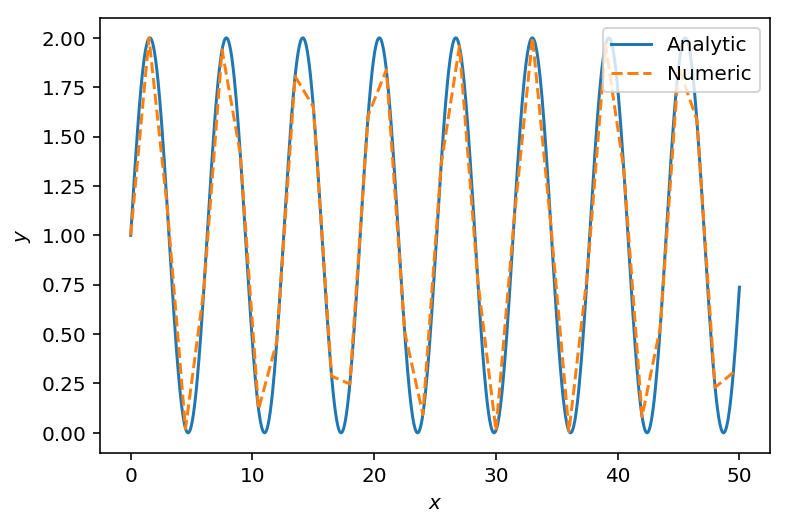

In [3]:
# define the number of points and the start and stop locations
dx = 1.5
start = 0
end = 50
y0 = np.cos(0)

# setup the x array, step size, and initialize y and y[0]
x = np.arange(start,end,dx)
N = len(x)
y = np.zeros(N)
y[0] = y0

# 4th Order Runge Kutta loop to solve for y[i+1]
for i in range(0,N-1):
    K1 = f(x[i]       , y[i]          )
    K2 = f(x[i]+0.5*dx, y[i]+0.5*dx*K1)
    K3 = f(x[i]+0.5*dx, y[i]+0.5*dx*K2)
    K4 = f(x[i]+dx    , y[i]+dx*K3    )
    
    y[i+1] = y[i]+(dx/6)*(K1+2*K2+2*K3+K4)
    
# plot the results ------------
fig, ax = plt.subplots()
# --- analytic solution
x_a = np.linspace(start,end,1000)
c1 = np.cos(0)
ax.plot(x_a,ysol(x_a), label='Analytic')
# --- numeric solution
ax.plot(x,y, '--', label='Numeric')
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
plt.legend(loc=1);

## More on the use of the 4th Order Runge-Kutta method

In this section we show how the solution can be changed for different ODE equations, and we show how the RG method can be placed in a function to make the method modular.

In [4]:
# a general setup function for the domain (t and y) and initial values (y0)

def setup(start,end,y0,stepsize):
    global t, y, N, dt # "global" will make arrays defined in the function available outside of the function
    dt = stepsize
    t = np.arange(start,end,dt)
    N = len(t)
    y = np.zeros(N)
    y[0] = y0
    return

# an assortment of different dy/dt = f(x,t)

def f1(t,y):
    return np.sin(t)+np.cos(y)

def f2(t,y):
    return t*np.sin(t)+np.cos(y)

def f3(t,y):
    return t*np.sin(t)-2*t*np.cos(y)

# the 4th-order Runge-Kutta method

def RK4(t,y,f,dt):
    for i in range(0,N-1):
        K1 = f(t[i]       , y[i]          )
        K2 = f(t[i]+0.5*dt, y[i]+0.5*dt*K1)
        K3 = f(t[i]+0.5*dt, y[i]+0.5*dt*K2)
        K4 = f(t[i]+dt    , y[i]+dt*K3    )
        y[i+1] = y[i]+(dt/6)*(K1+2*K2+2*K3+K4)
    return y

The cell below allows for one to play with different domain setups and ODEs to integrate.

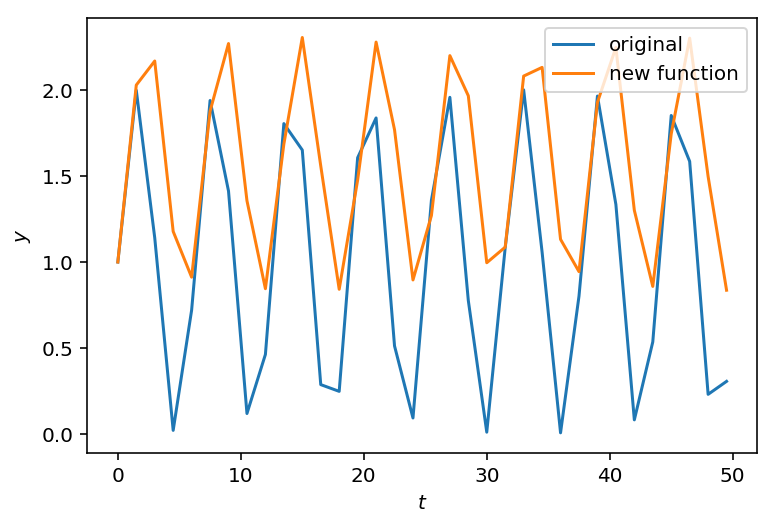

In [5]:
# setup(start,end,y0,stepsize).
setup(0,50,np.cos(0),1.5)

# numerical solution RK4(y,ySolution,dy/dy function to integrate, setpsize)
y_original = RK4(t,y,f,dt).copy()
y2 = RK4(t,y,f1,dt).copy()

# plot the results ------------
fig, ax = plt.subplots()
ax.plot(t,y_original, label='original')
ax.plot(t,y2, label='new function')
ax.set_xlabel('$t$')
ax.set_ylabel('$y$')
plt.legend();